# Supplementary Fig S6 · Spindle's gene-list and whole-tile search on skin

The old Fig 7 (`_backup_2026-11-01/F7_skin.ipynb`) with Spindle only (user, 1 Nov): A and B show Spindle's first 10
tiles (R7 rerun for skin seed 0); the old C–E (every section: composition difference, Cliff's δ, co-variation lift)
are dropped.

* **Needs:** `R7_queries.ipynb` (results/queries/).
* **Writes:** `figures/figS6_skin/panels/{A,B}.{pdf,png}` and `figures/figS6_skin/figS6_skin.{pdf,png}`.

Panels:
* **A:** gene-list search on skin. The three skin signatures; cells coloured by signature score; Spindle's first 10
  tiles outlined.
* **B:** whole-tile search on skin. A held-out epidermis tile (rule in `queries.py`) and Spindle's first 10, on the
  section and up close; the class compositions; every skin held-out query against a random 10.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib import colormaps
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.patches import Patch, Rectangle

import style as ps

FIG = "figS6_skin"
RES = ps.ROOT / "results" / "queries"
EX = RES / "skin_example"
SIG = [("Melanocyte_Tumor", "Melanocyte"), ("Keratinocyte_Epidermis", "Keratinocyte"),
       ("Immune_Infiltrate", "Immune")]
CLASS_COLORS = ["#882255", "#EE7733", "#33BBEE", "#DDDDDD"]  # melanocyte, keratinocyte, immune, other
SPINDLE = ps.TIER_COLORS["spindle"]
HIT = ps.INK  # Spindle's tiles on the maps (the query is ps.QUERY_COLOR)


def at(fig, x, y, w, h, **kw):
    """Axes w x h mm at (x, y) mm from the panel's top-left corner."""
    W, H = ps.size_mm(fig)
    return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H], **kw)


def text(fig, x, y, s, size=ps.LABEL_PT, ha="left", **kw):
    W, H = ps.size_mm(fig)
    fig.text(x / W, 1 - y / H, s, fontsize=size, ha=ha, va="top", **kw)


def legend(fig, cx, cy, handles, ncol, **kw):
    W, H = ps.size_mm(fig)
    fig.legend(handles=handles, ncol=ncol, loc="center", bbox_to_anchor=(cx / W, 1 - cy / H), **kw)


def hbar(fig, x, y, w, cmap, vmin, vmax, ticks):
    ax = at(fig, x, y, w, 2.5)
    cb = fig.colorbar(ScalarMappable(Normalize(vmin, vmax), cmap), cax=ax, orientation="horizontal", ticks=ticks)
    cb.outline.set_linewidth(0.5)
    return cb


def spatial(ax, x0, x1, y0, y1):
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)  # image orientation
    ax.set_aspect("equal")
    ax.axis("off")


def extent(xy, w):
    (x0, y0), (x1, y1) = xy.min(0), xy.max(0)
    return x0, x1, y0, y1, w * (y1 - y0) / (x1 - x0)

## A · Gene-list search on skin

figures/figS6_skin/panels/A.pdf/.png: 180 x 45 mm, 1.3 / 2.0 MB


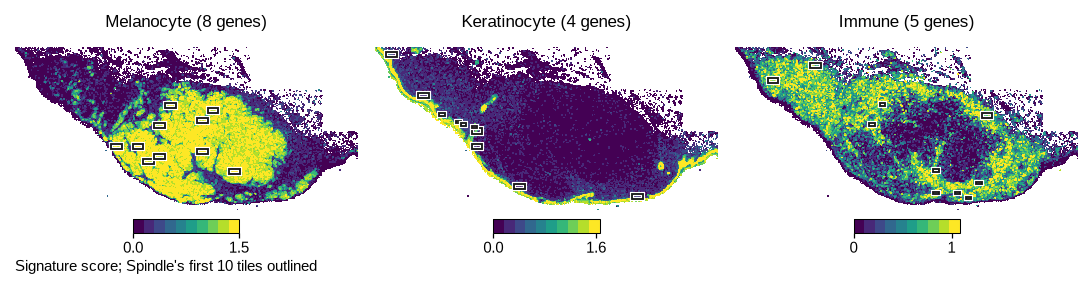

In [2]:
SIG_W, A_W, A_H = 58.0, 180.0, 45.0


def panel_a(fig):
    z = np.load(EX / "signature_cells.npz")
    xy = z["xy"]
    x0, x1, y0, y1, h = extent(xy, SIG_W)
    cmap = ListedColormap(colormaps["viridis"](np.linspace(0, 1, 10)))  # 10 steps keep the PNG within budget
    L = pd.read_csv(RES / "lists.csv")
    n_genes = L[(L.key == "skin_melanoma") & (L.method == "spindle_partial")].set_index("list").n_genes
    for i, (name, label) in enumerate(SIG):
        x = 61.0 * i
        s = z[f"score_{name}"].astype(np.float32)
        vmax = float(np.quantile(s, 0.995))
        ax = at(fig, x, 6, SIG_W, h)
        o = np.argsort(s, kind="stable")
        ax.scatter(xy[o, 0], xy[o, 1], s=0.12, c=s[o], cmap=cmap, vmin=0, vmax=vmax, lw=0, rasterized=True,
                   antialiased=False)
        for bx0, by0, bx1, by1 in z[f"top_{name}"]:
            for ec, lw in (("white", 2.0), (HIT, 0.9)):  # white halo: visible on dark and bright cells
                ax.add_patch(Rectangle((bx0, by0), bx1 - bx0, by1 - by0, fill=False, ec=ec, lw=lw, zorder=3))
        spatial(ax, x0, x1, y0, y1)
        text(fig, x + SIG_W / 2, 0.5, f"{label} ({int(n_genes[name])} genes)", ha="center")
        hbar(fig, x + 20, 35, 18, cmap, 0, vmax, [0, np.floor(10 * vmax) / 10])
    text(fig, 0, 42, "Signature score; Spindle's first 10 tiles outlined", size=ps.TICK_PT)


fig = ps.panel(A_W, A_H)
panel_a(fig)
ps.save_panel(fig, FIG, "A")

## B · Whole-tile search on skin

figures/figS6_skin/panels/B.pdf/.png: 180 x 45 mm, 0.6 / 1.4 MB


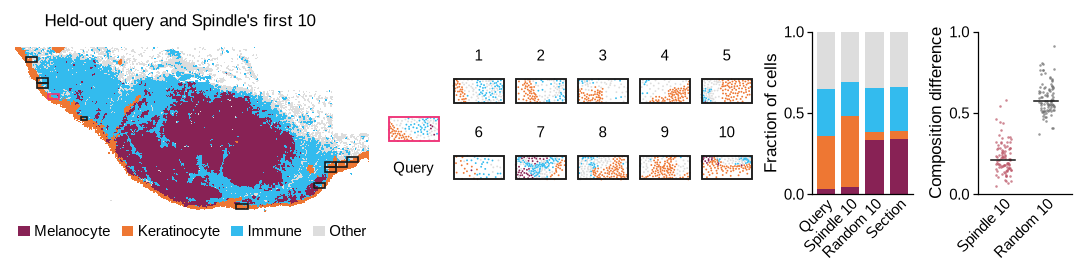

In [3]:
B_W, B_H = 180.0, 45.0
TX, TY, TS = 63.0, 9.0, 10.5  # thumbnails: hit 1 x, first row y, step


def panel_b(fig):
    z = np.load(EX / "example_cells.npz")
    names = [str(n) for n in z["classes"]]
    col = np.array(CLASS_COLORS)
    xy, cls = z["xy"], z["cls"]
    text(fig, 5, 0.5, "Held-out query and Spindle's first 10")
    x0, x1, y0, y1, h = extent(xy, 60.0)
    ax = at(fig, 0, 6, 60.0, h)
    o = np.argsort(cls != len(names) - 1, kind="stable")  # "Other" underneath
    ax.scatter(xy[o, 0], xy[o, 1], s=0.12, c=col[cls[o]], lw=0, rasterized=True, antialiased=False)
    for k in range(len(z["tiles"]) - 1, -1, -1):
        bx0, by0, bx1, by1 = z[f"bbox{k}"]
        ax.add_patch(Rectangle((bx0, by0), bx1 - bx0, by1 - by0, fill=False, lw=0.8,
                               ec=ps.QUERY_COLOR if k == 0 else HIT, zorder=3 if k == 0 else 2))
    spatial(ax, x0, x1, y0, y1)
    legend(fig, 30, 6 + h + 3, [Patch(fc=c, ec="none", label=n) for n, c in zip(names, CLASS_COLORS)], 4,
           handlelength=0.8, columnspacing=0.8, handletextpad=0.3)

    for k in range(len(z["tiles"])):
        if k == 0:
            x, y = TX, TY + 6.5
        else:
            x, y = TX + 11 + TS * ((k - 1) % 5), TY + (0 if k <= 5 else 13)
            text(fig, x + 4.5, y - 2.5, str(k), size=ps.TICK_PT, ha="center")
        bx0, by0, bx1, by1 = z[f"bbox{k}"]
        side = max(bx1 - bx0, by1 - by0) * 1.06
        cx, cy = (bx0 + bx1) / 2, (by0 + by1) / 2
        ax = at(fig, x, y, 9, 9)
        ax.scatter(*z[f"xy{k}"].T, s=0.8, c=col[z[f"cls{k}"]], lw=0, rasterized=True)
        ax.add_patch(Rectangle((bx0, by0), bx1 - bx0, by1 - by0, fill=False, lw=0.9,
                               ec=ps.QUERY_COLOR if k == 0 else HIT))
        spatial(ax, cx - side / 2, cx + side / 2, cy - side / 2, cy + side / 2)
    text(fig, TX + 4.5, TY + 16.5, "Query", size=ps.TICK_PT, ha="center")

    ex = pd.read_csv(EX / "example.csv").set_index("set")
    sets = [("query", "Query"), ("top10", "Spindle 10"), ("random10", "Random 10"), ("section", "Section")]
    ax = at(fig, 135, 3.5, 17, 27.5)
    for i, (s, _) in enumerate(sets):
        bottom = 0.0
        for n, c in zip(names, CLASS_COLORS):
            v = ex.loc[s, n]
            ax.bar(i, v, 0.75, bottom=bottom, color=c, lw=0)
            bottom += v
    ax.set_xticks(range(len(sets)))
    ax.set_xticklabels([l for _, l in sets], rotation=45, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel("Fraction of cells")

    q = pd.read_csv(RES / "per_dataset" / "skin_melanoma" / "seed0_tile_queries.csv")  # the example's seed (queries.EXAMPLE_SEED)
    ax = at(fig, 163, 3.5, 16, 27.5)
    rng = np.random.default_rng(0)
    for i, (c, color) in enumerate((("tv_spindle", SPINDLE), ("tv_random", ps.MUTED))):
        v = q[c].to_numpy()
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=1.5, c=color, lw=0, alpha=0.7, zorder=2)
        ax.plot([i - 0.28, i + 0.28], [np.median(v)] * 2, color=ps.INK, lw=0.75, zorder=3)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Spindle 10", "Random 10"], rotation=45, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel("Composition difference")


fig = ps.panel(B_W, B_H)
panel_b(fig)
ps.save_panel(fig, FIG, "B")

## Full figure

figures/figS6_skin/figS6_skin.pdf/.png: 180 x 92 mm, 1.9 / 3.3 MB


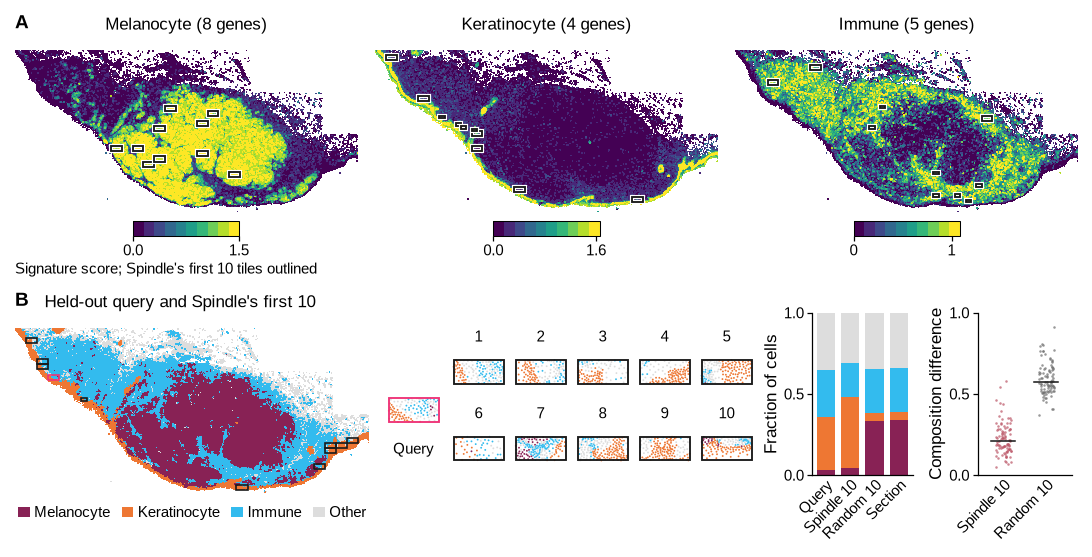

In [4]:
page = ps.page(180, 92)
panel_a(ps.place(page, "A", 0, 0, A_W, A_H))
panel_b(ps.place(page, "B", 0, 47, B_W, B_H))
ps.save_figure(page, FIG)